# Шаг 4. Простая свёрточная сеть учится отличать кошек от собак

Соберём свою первую **свёрточную нейросеть** (CNN, *convolutional neural network*) из кирпичиков шага 2.

**Архитектура `SimpleCNN`** (в `common.py`):

| Часть | Слой | Форма выхода | Что происходит |
|-------|------|--------------|----------------|
| вход | — | 3 × 32 × 32 | цветная картинка |
| блок 1 | `Conv2d(3, 16, 3)` → `ReLU` → `MaxPool2d(2)` | 16 × 16 × 16 | 16 простых узоров: границы, пятна цвета |
| блок 2 | `Conv2d(16, 32, 3)` → `ReLU` → `MaxPool2d(2)` | 32 × 8 × 8 | 32 узора из узоров: углы, дуги, текстура шерсти |
| блок 3 | `Conv2d(32, 64, 3)` → `ReLU` → `MaxPool2d(2)` | 64 × 4 × 4 | 64 сложных признака: «что-то похожее на глаз, ухо, нос» |
| классификатор | `Flatten` → `Linear(1024, 64)` → `ReLU` → `Linear(64, 2)` | 2 | по найденным признакам решает: кошка или собака |

Идея — **иерархия признаков**: каждый следующий блок собирает узоры предыдущего в более сложные.
С каждым пулингом карта уменьшается вдвое, поэтому одно окно 3 × 3 на блоке 3 «видит» уже большую часть исходной картинки.
Число каналов при этом растёт: меньше «где», больше «что».

**Структура примера (алгоритм):**
1. Создаём сеть, сравниваем число весов с MLP.
2. Пропускаем пустую картинку через блоки и печатаем, как меняется форма.
3. Обучаем 25 эпох тем же циклом, что и MLP.
4. Сохраняем сеть в `cnn.pt`, историю — в `cnn.json`.
5. Рисуем графики точности рядом с MLP и обсуждаем переобучение.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session04")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `CatsDogs(train, transform)` | набор данных: только кошки и собаки из CIFAR-10. Обучающий (`train=True`) — 10 000 картинок, проверочный — 2 000. Метки: 0 — кошка, 1 — собака |
| `CLASSES`, `CLASSES_RU` | названия классов: `["cat", "dog"]` и `["кошка", "собака"]` |
| `MLP` | полносвязная сеть из сессии 3, только вход 3 × 32 × 32 = 3072 числа |
| `SimpleCNN(dropout)` | простая свёрточная сеть: три блока «свёртка → ReLU → пулинг» и классификатор |
| `train(model, train_set, test_set, epochs)` | цикл обучения из сессии 3; после каждой эпохи пишет точность на обучающих и проверочных картинках |
| `accuracy`, `predict_all` | точность сети на наборе и вероятности классов для всех картинок |
| `save_model`, `load_model`, `load_history` | сохранить / загрузить веса (`*.pt`) и историю обучения (`*.json`) |
| `count_params(model)` | сколько весов в сети |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session04`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. CIFAR-10 берётся из локальной папки `data/cifar-10-batches-py`, интернет не нужен.

## 1. Сеть и её размер

Сравним число весов: у свёрточной сети их **в несколько раз меньше**, чем у MLP,
потому что каждое ядро 3 × 3 используется во всех позициях картинки (общие веса).

In [1]:
import matplotlib.pyplot as plt
import torch

from common import MLP, CatsDogs, SimpleCNN, count_params, load_history, save_model, show, train

torch.manual_seed(0)
train_set, test_set = CatsDogs(train=True), CatsDogs(train=False)

model = SimpleCNN()
print(model)
print("Весов в свёрточной сети:", count_params(model))
print("Весов в MLP из шага 3:  ", count_params(MLP()))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.0, inplace=False)
    (2): Linear(in_features=1024, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.0, inplace=False)
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
)
Весов в свёрточной сети: 89314
Весов в MLP из шага 3:   803266


## 2. Как меняется форма по слоям

Пропустим через блоки свёртки «пустую» картинку из нулей `torch.zeros(1, 3, 32, 32)` и напечатаем форму после каждого слоя.
`type(layer).__name__` — имя класса слоя (`Conv2d`, `ReLU`, `MaxPool2d`).

Видно, что `Conv2d` меняет число каналов, но не размер (благодаря `padding=1`), `ReLU` ничего не меняет в форме,
а `MaxPool2d` уменьшает высоту и ширину вдвое. В конце получается `64 × 4 × 4 = 1024` числа — их и получает классификатор.

In [2]:
x = torch.zeros(1, 3, 32, 32)
print(f"{'вход':>10}: {tuple(x.shape)}")
for layer in model.features:
    x = layer(x)
    print(f"{type(layer).__name__:>10}: {tuple(x.shape)}")

      вход: (1, 3, 32, 32)
    Conv2d: (1, 16, 32, 32)
      ReLU: (1, 16, 32, 32)
 MaxPool2d: (1, 16, 16, 16)
    Conv2d: (1, 32, 16, 16)
      ReLU: (1, 32, 16, 16)
 MaxPool2d: (1, 32, 8, 8)
    Conv2d: (1, 64, 8, 8)
      ReLU: (1, 64, 8, 8)
 MaxPool2d: (1, 64, 4, 4)


## 3. Обучение

Цикл обучения **тот же самый**, что для MLP: изменилась только архитектура сети.
Свёрточная сеть считает больше операций на картинку, поэтому эпоха идёт дольше, чем у MLP. 25 эпох на обычном ноутбуке — около 1–2 минут.

In [3]:
history = train(model, train_set, test_set, epochs=25)
save_model(model, "cnn", history)

Эпоха  1: на обучающих 59.5%, на проверочных 67.1%
Эпоха  2: на обучающих 68.3%, на проверочных 70.9%
Эпоха  3: на обучающих 71.3%, на проверочных 71.6%
Эпоха  4: на обучающих 74.1%, на проверочных 73.5%
Эпоха  5: на обучающих 75.5%, на проверочных 73.8%
Эпоха  6: на обучающих 78.1%, на проверочных 75.7%
Эпоха  7: на обучающих 78.9%, на проверочных 74.7%
Эпоха  8: на обучающих 80.4%, на проверочных 73.8%
Эпоха  9: на обучающих 81.8%, на проверочных 76.3%
Эпоха 10: на обучающих 83.5%, на проверочных 75.8%
Эпоха 11: на обучающих 84.5%, на проверочных 76.2%
Эпоха 12: на обучающих 86.4%, на проверочных 77.7%
Эпоха 13: на обучающих 88.5%, на проверочных 76.6%
Эпоха 14: на обучающих 89.7%, на проверочных 76.7%
Эпоха 15: на обучающих 91.1%, на проверочных 75.9%
Эпоха 16: на обучающих 92.7%, на проверочных 75.8%
Эпоха 17: на обучающих 93.0%, на проверочных 76.7%
Эпоха 18: на обучающих 93.9%, на проверочных 76.2%
Эпоха 19: на обучающих 95.5%, на проверочных 76.7%
Эпоха 20: на обучающих 96.0%, н

## 4. Сравнение с MLP и переобучение

На графике три линии: свёрточная сеть на обучающих и проверочных картинках и MLP на проверочных (из `mlp.json`, если шаг 3 выполнен).

Что обычно видно:
1. На проверочных картинках свёрточная сеть **заметно лучше** MLP — примерно 75–78% против ~62%, хотя весов у неё меньше.
2. Но после нескольких эпох точность на **обучающих** продолжает расти к 90%+, а на **проверочных** — останавливается
   или даже падает. Разрыв между линиями — это **переобучение**: сеть начинает запоминать конкретные фотографии.

Как с этим бороться — в шаге 5.

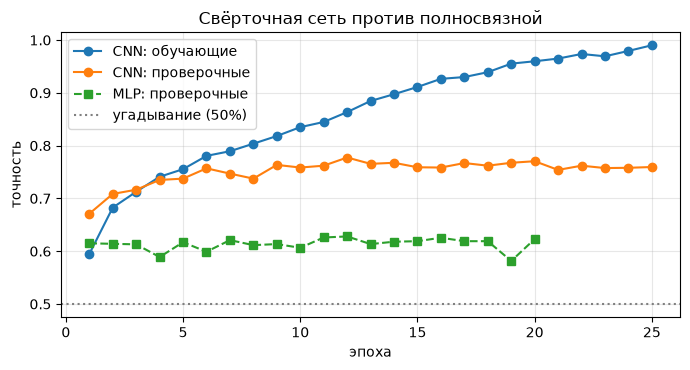

In [4]:
epochs = range(1, len(history["train"]) + 1)
plt.figure(figsize=(7, 3.8))
plt.plot(epochs, history["train"], "o-", label="CNN: обучающие")
plt.plot(epochs, history["test"], "o-", label="CNN: проверочные")
mlp = load_history("mlp")
if mlp:
    plt.plot(range(1, len(mlp["test"]) + 1), mlp["test"], "s--", label="MLP: проверочные")
plt.axhline(0.5, color="gray", linestyle=":", label="угадывание (50%)")
plt.xlabel("эпоха")
plt.ylabel("точность")
plt.title("Свёрточная сеть против полносвязной")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cnn_curves.png", dpi=100)
show()

## Попробуйте сами

1. Уберите третий блок свёртки (и поменяйте вход классификатора на `32 * 8 * 8`). Как изменились точность и число весов?
2. Удвойте число каналов во всех блоках (32, 64, 128). Растёт ли точность на проверке? А время обучения?
3. Замените `kernel_size=3` на `5` (и `padding=2`). Что изменилось?
4. На какой эпохе точность на проверке была максимальной? Как можно было бы сохранить сеть именно с этой эпохи?